# 06 – Đánh giá hiệu năng mô hình 

**Mục tiêu:** đánh giá hai mô hình đã huấn luyện ở notebook 05 trên **tập test** (1.600 sản phẩm) và tìm yếu tố quan trọng nhất (RQ4).

**Nội dung**
1. Đọc dữ liệu test và nạp mô hình đã lưu.
2. Các chỉ số: Accuracy, Precision, Recall, F1-score (macro và theo từng lớp).
3. Ma trận nhầm lẫn (Confusion Matrix).
4. ROC-AUC.
5. Độ quan trọng của đặc trưng (Feature Importance).
6. Phần mở rộng: đối chiếu với Nutri-Score và hiệu năng theo danh mục.
7. So sánh K-Means với nhãn tự xây dựng (Crosstab, Heatmap, ARI, NMI).
8. So sánh Logistic Regression và Random Forest (Accuracy, Macro F1, Weighted F1, F1 theo từng nhãn).

Mô hình tốt nhất được chọn theo **F1 macro cross-validation trên tập train** (notebook 05), không chọn theo điểm test để tập test không tham gia vào việc lựa chọn.

| | |
|---|---|
| **Đầu vào** | `train.csv`, `test.csv`, `feature_dataset.csv`, `cv_results.csv`, hai file mô hình `.joblib` (do notebook 05 tạo ra) |
| **Đầu ra** | `test_metrics.csv`, `feature_importance.csv`, `performance_by_category.csv`, `best_model.csv`, `kmeans_vs_label_crosstab.csv`, `kmeans_vs_label_metrics.csv`, `model_comparison.csv`, `per_class_metrics.csv`, `ml_*.png` |

## 1. Đọc dữ liệu và nạp mô hình

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score, auc)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

SEED = 42
LABELS = ["Healthy", "Moderate", "Less Healthy"]
LABEL_NUTRIENTS = ["fat_100g", "saturated-fat_100g", "sugars_100g", "salt_100g"]
# Phải trùng với FEATURES đã chọn ở notebook 04 (không chứa 4 chất tạo nhãn)
FEATURES = ["energy-kcal_100g", "proteins_100g", "fiber_100g", "additives_n", "protein_energy_share", "has_fiber"]
assert not set(LABEL_NUTRIENTS) & set(FEATURES), "Đặc trưng không được chứa 4 chất tạo nhãn"

test = pd.read_csv("test.csv", dtype={"code": str})
y_test = test["health_label"]
Xte = test[FEATURES + ["main_category"]]
print("test:", test.shape)

fitted = {"Logistic Regression": joblib.load("model_logistic_regression.joblib"),
          "Random Forest": joblib.load("model_random_forest.joblib")}
cv_res = pd.read_csv("cv_results.csv")
best_name = cv_res.sort_values("CV_f1_macro", ascending=False).iloc[0]["mo_hinh"]
print("Mô hình tốt nhất theo F1 macro cross-validation (train):", best_name)

test: (1600, 20)
Mô hình tốt nhất theo F1 macro cross-validation (train): Random Forest


## 2. Accuracy, Precision, Recall, F1-score

In [2]:
# Chỉ số tổng hợp trên tập test (Precision, Recall, F1 là trung bình macro: mỗi lớp có trọng số như nhau)
rows, proba, preds = [], {}, {}
for name, pipe in fitted.items():
    preds[name] = pipe.predict(Xte)
    proba[name] = pipe.predict_proba(Xte)
    rows.append({"mo_hinh": name,
                 "Accuracy": accuracy_score(y_test, preds[name]),
                 "Precision_macro": precision_score(y_test, preds[name], average="macro"),
                 "Recall_macro": recall_score(y_test, preds[name], average="macro"),
                 "F1_macro": f1_score(y_test, preds[name], average="macro"),
                 "ROC_AUC_macro_ovr": roc_auc_score(y_test, proba[name], multi_class="ovr", average="macro",
                                                   labels=list(pipe.classes_))})
test_metrics = pd.DataFrame(rows)
print(test_metrics.round(3).to_string(index=False))
test_metrics.to_csv("test_metrics.csv", index=False, encoding="utf-8-sig")

best = fitted[best_name]
pred = preds[best_name]
print("\nSo sánh F1 macro: cross-validation (train) và test")
print(cv_res[["mo_hinh", "CV_f1_macro"]].merge(test_metrics[["mo_hinh", "F1_macro"]], on="mo_hinh").round(3).to_string(index=False))

            mo_hinh  Accuracy  Precision_macro  Recall_macro  F1_macro  ROC_AUC_macro_ovr
Logistic Regression     0.784            0.761         0.764     0.761              0.908
      Random Forest     0.836            0.824         0.831     0.827              0.950

So sánh F1 macro: cross-validation (train) và test
            mo_hinh  CV_f1_macro  F1_macro
Logistic Regression        0.774     0.761
      Random Forest        0.827     0.827


**Nhận xét:**
- **Random Forest** vượt Logistic Regression ở mọi chỉ số trên tập test: accuracy 0,836 so với 0,784; precision macro 0,824 so với 0,761; recall macro 0,831 so với 0,764; F1 macro 0,827 so với 0,761; ROC-AUC macro 0,950 so với 0,908.
- Điểm test sát điểm cross-validation (F1 macro của Random Forest: 0,827 và 0,827; của Logistic Regression: 0,774 và 0,761), nên không có dấu hiệu overfit rõ rệt.
- Random Forest cũng là mô hình được chọn theo cross-validation, nên việc chọn mô hình không dựa vào tập test.

In [3]:
# Báo cáo theo từng lớp (Precision, Recall, F1) cho hai mô hình
for name in fitted:
    print("=" * 60); print(name); print("=" * 60)
    print(classification_report(y_test, preds[name], labels=LABELS, digits=3))

Logistic Regression
              precision    recall  f1-score   support

     Healthy      0.850     0.857     0.854       687
    Moderate      0.617     0.541     0.577       423
Less Healthy      0.815     0.892     0.852       490

    accuracy                          0.784      1600
   macro avg      0.761     0.764     0.761      1600
weighted avg      0.778     0.784     0.780      1600

Random Forest
              precision    recall  f1-score   support

     Healthy      0.921     0.844     0.881       687
    Moderate      0.691     0.745     0.717       423
Less Healthy      0.862     0.904     0.882       490

    accuracy                          0.836      1600
   macro avg      0.824     0.831     0.827      1600
weighted avg      0.842     0.836     0.838      1600



**Nhận xét theo lớp (Random Forest):** Healthy (precision 0,921, recall 0,844) và Less Healthy (0,862 / 0,904) được nhận ra tốt; **Moderate yếu nhất** (0,691 / 0,745, F1 0,717) vì là nhóm trung gian của quy tắc gán nhãn (không đủ "xanh" để là Healthy, chưa đủ "đỏ" để là Less Healthy) nên ranh giới sát hai lớp bên cạnh. Logistic Regression yếu hơn rõ ở Moderate: recall chỉ 0,541 (F1 0,577), tức gần một nửa số sản phẩm Moderate bị gán sang lớp khác.

## 3. Ma trận nhầm lẫn (Confusion Matrix)

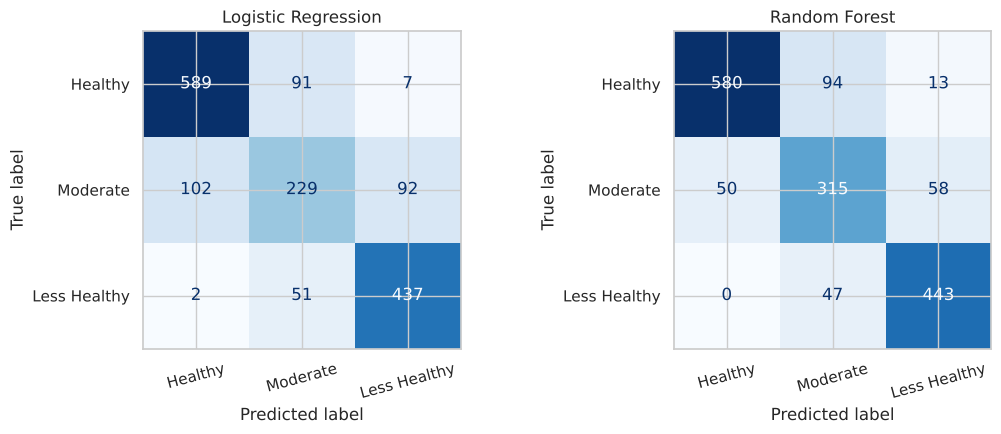

In [4]:
# Ma trận nhầm lẫn: so sánh hai mô hình
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, ["Logistic Regression", "Random Forest"]):
    p = fitted[name].predict(Xte)
    ConfusionMatrixDisplay.from_predictions(y_test, p, labels=LABELS, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig("ml_confusion_matrix.png", dpi=120)
plt.show()

**Nhận xét:** với Random Forest, hầu hết lỗi xảy ra giữa các lớp **kề nhau**: 94 sản phẩm Healthy bị đoán Moderate, 50 Moderate bị đoán Healthy, 47 Less Healthy bị đoán Moderate và 58 Moderate bị đoán Less Healthy. Rất hiếm khi nhầm hai đầu mút (chỉ 13 Healthy bị đoán Less Healthy và không có trường hợp ngược lại), nên mức độ sai lệch nhìn chung nhẹ.

## 4. ROC-AUC

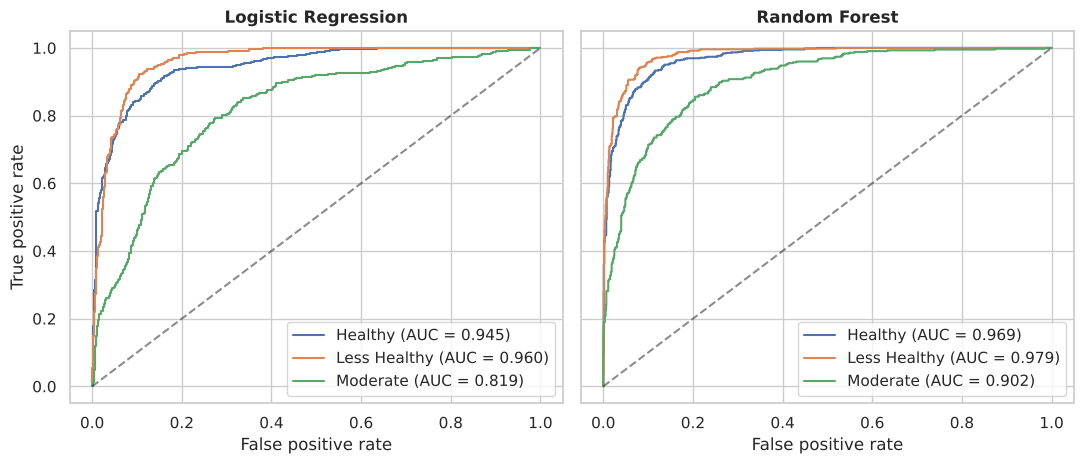

              Logistic Regression  Random Forest
Healthy                     0.945          0.969
Moderate                    0.819          0.902
Less Healthy                0.960          0.979


In [5]:
# ROC one-vs-rest cho cả hai mô hình
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
auc_tab = {}
for ax, (name, pipe) in zip(axes, fitted.items()):
    classes = list(pipe.classes_)
    Y = label_binarize(y_test, classes=classes)
    auc_tab[name] = {}
    for i, cl in enumerate(classes):
        fpr, tpr, _ = roc_curve(Y[:, i], proba[name][:, i])
        auc_tab[name][cl] = auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f"{cl} (AUC = {auc_tab[name][cl]:.3f})")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
    ax.set_title(name, fontweight="bold")
    ax.set_xlabel("False positive rate")
    ax.legend(loc="lower right")
axes[0].set_ylabel("True positive rate")
plt.tight_layout()
plt.savefig("ml_roc.png", dpi=120)
plt.show()

print(pd.DataFrame(auc_tab).reindex(LABELS).round(3))
auc_rows = auc_tab[best_name]

**Nhận xét:** AUC one-vs-rest của Random Forest cao ở cả ba lớp: Less Healthy 0,979, Healthy 0,969 và Moderate 0,902 (macro 0,950). Logistic Regression thấp hơn: 0,960, 0,945 và 0,819 (macro 0,908). Moderate thấp nhất ở cả hai mô hình, đúng với kết quả phân loại ở trên.

## 5. Độ quan trọng của đặc trưng (Feature Importance, RQ4)

           dac_trung  giam_F1    std
    energy-kcal_100g   0.4538 0.0108
       main_category   0.1161 0.0066
          fiber_100g   0.0353 0.0034
protein_energy_share   0.0296 0.0050
       proteins_100g   0.0239 0.0041
         additives_n   0.0205 0.0039
           has_fiber   0.0025 0.0015


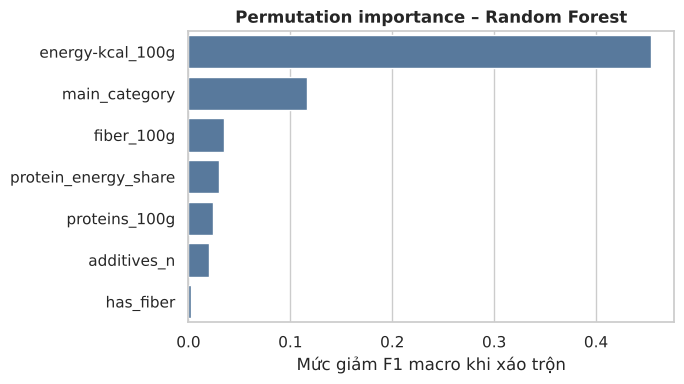

In [6]:
# Permutation importance trên tập test: đo F1 giảm bao nhiêu khi xáo trộn một đặc trưng
feat_names = FEATURES + ["main_category"]
pi = permutation_importance(best, Xte, y_test, n_repeats=20, random_state=SEED, scoring="f1_macro", n_jobs=-1)
imp = pd.DataFrame({"dac_trung": feat_names, "giam_F1": pi.importances_mean, "std": pi.importances_std}).sort_values("giam_F1", ascending=False)
print(imp.round(4).to_string(index=False))

plt.figure(figsize=(7, 4))
sns.barplot(data=imp, y="dac_trung", x="giam_F1", color="#4c78a8")
plt.title(f"Permutation importance – {best_name}", fontweight="bold")
plt.xlabel("Mức giảm F1 macro khi xáo trộn")
plt.ylabel("")
plt.tight_layout()
plt.savefig("ml_feature_importance.png", dpi=120)
plt.show()

**Nhận xét (RQ4):**
- **Năng lượng** áp đảo: xáo trộn nó làm F1 giảm 0,45, gấp gần 4 lần biến đứng thứ hai.
- Tiếp theo là **danh mục sản phẩm** (giảm 0,116), rồi chất xơ (0,035), % năng lượng từ đạm (0,030), đạm (0,024) và phụ gia (0,021); `has_fiber` gần như không đóng góp (0,003).
- Lưu ý: năng lượng được tính từ béo, đường, đạm nên nó mang theo thông tin gián tiếp về béo và đường. Vì vậy kết luận hợp lý là: nhãn chất lượng chủ yếu do **mật độ năng lượng** quyết định, chứ không nên hiểu là béo và đường không quan trọng.

In [7]:
# Hệ số Logistic Regression (cho biết chiều ảnh hưởng, đã chuẩn hóa nên so sánh được)
lr = fitted["Logistic Regression"]
names = FEATURES + list(lr.named_steps["pre"].named_transformers_["cat"].get_feature_names_out(["main_category"]))
coef = pd.DataFrame(lr.named_steps["model"].coef_, index=lr.named_steps["model"].classes_, columns=names).T
print(coef.round(2).loc[FEATURES])

                      Healthy  Less Healthy  Moderate
energy-kcal_100g        -3.24          3.36     -0.12
proteins_100g           -0.63          0.60      0.03
fiber_100g               0.32         -0.28     -0.04
additives_n             -0.13          0.11      0.02
protein_energy_share     0.62         -0.74      0.12
has_fiber                0.14         -0.17      0.03


**Nhận xét:** hệ số Logistic Regression (đã chuẩn hóa) khớp với trực giác: năng lượng cao làm tăng khả năng Less Healthy (+3,36) và giảm khả năng Healthy (−3,24). Đạm tuyệt đối cao đi nhẹ về phía Less Healthy (+0,60) trong khi % năng lượng từ đạm cao đi về phía Healthy (+0,62): sản phẩm nhiều đạm tuyệt đối thường là phô mai, thịt (nhiều béo, năng lượng cao), còn tỷ lệ đạm trên năng lượng cao thường là sản phẩm nhẹ, ít béo. Phụ gia có hệ số rất nhỏ.

## 6. Phần mở rộng

### 6.1 Đối chiếu với Nutri-Score (kiểm chứng chéo)

In [8]:
# Chỉ xét sản phẩm test có Nutri-Score
t = test.copy()
t["pred"] = pred
t["nutri_3"] = t["nutriscore_grade"].map({"A": "Healthy", "B": "Healthy", "C": "Moderate", "D": "Less Healthy", "E": "Less Healthy"})
t = t.dropna(subset=["nutri_3"])
print("Số sản phẩm test có Nutri-Score:", len(t))
print("Nhãn FSA (thật) khớp Nutri-Score gộp :", round((t["health_label"] == t["nutri_3"]).mean() * 100, 1), "%")
print("Mô hình dự đoán khớp Nutri-Score gộp:", round((t["pred"] == t["nutri_3"]).mean() * 100, 1), "%")
print("Mô hình dự đoán khớp nhãn FSA        :", round((t["pred"] == t["health_label"]).mean() * 100, 1), "%")
print("\nHàng: Nutri-Score gộp, cột: dự đoán của mô hình")
print(pd.crosstab(t["nutri_3"], t["pred"]).reindex(index=LABELS, columns=LABELS))

Số sản phẩm test có Nutri-Score: 1515
Nhãn FSA (thật) khớp Nutri-Score gộp : 67.3 %
Mô hình dự đoán khớp Nutri-Score gộp: 65.4 %
Mô hình dự đoán khớp nhãn FSA        : 84.0 %

Hàng: Nutri-Score gộp, cột: dự đoán của mô hình
pred          Healthy  Moderate  Less Healthy
nutri_3                                      
Healthy           329        52             8
Moderate          189       228            53
Less Healthy       73       149           434


**Nhận xét:**
- Mô hình dự đoán khớp nhãn FSA ở mức 84,0% trong khi khớp Nutri-Score gộp 65,4%, gần bằng mức khớp giữa chính nhãn FSA và Nutri-Score (67,3%). Điều này cho thấy mô hình học đúng **nhãn của nhóm**, và sự lệch với Nutri-Score chủ yếu do hai hệ thống chấm khác nhau (Nutri-Score tính thêm đạm, chất xơ, rau quả), không phải do mô hình sai.
- Phần lớn sai lệch là sản phẩm Nutri-Score Moderate (C) bị mô hình đoán Healthy (189 sản phẩm) hoặc Nutri-Score Less Healthy (D, E) bị đoán Moderate (149).

### 6.2 Hiệu năng theo danh mục và lưu kết quả

In [9]:
t2 = test.copy()
t2["pred"] = pred
by_cat = pd.DataFrame({
    cat: {"n": len(g), "accuracy": accuracy_score(g["health_label"], g["pred"]),
          "f1_macro": f1_score(g["health_label"], g["pred"], average="macro")}
    for cat, g in t2.groupby("main_category")}).T
by_cat.index.name = "main_category"
print(by_cat.round(3))

imp.to_csv("feature_importance.csv", index=False, encoding="utf-8-sig")
by_cat.to_csv("performance_by_category.csv", encoding="utf-8-sig")
pd.DataFrame({"best_model": best_name, "class": list(auc_rows), "auc": [float(v) for v in auc_rows.values()]}).to_csv(
    "best_model.csv", index=False, encoding="utf-8-sig")
print("Đã lưu feature_importance.csv, performance_by_category.csv, best_model.csv")

                   n  accuracy  f1_macro
main_category                           
beverages      283.0     0.894     0.797
dairies        443.0     0.916     0.891
meals          433.0     0.755     0.609
snacks         441.0     0.798     0.699
Đã lưu feature_importance.csv, performance_by_category.csv, best_model.csv


**Nhận xét:** mô hình hoạt động tốt nhất ở dairies (accuracy 0,916, F1 0,891). Beverages có accuracy 0,894 nhưng F1 macro chỉ 0,797 vì lớp Less Healthy rất ít mẫu (14 sản phẩm trong tập test). Kém hơn ở snacks (F1 0,699) và nhất là meals (0,609): meals chỉ có 16 sản phẩm Less Healthy trong tập test và mô hình chỉ nhận ra khoảng 19% trong số đó, kéo F1 macro xuống dù accuracy vẫn đạt 0,755. Khi triển khai cần báo cáo theo danh mục chứ không chỉ một con số chung.

## 7. So sánh K-Means với nhãn tự xây dựng (Healthy / Moderate / Less Healthy)

**Mục đích:** K-Means là phương pháp **không giám sát**, không hề biết nhãn của nhóm. Nếu các cụm K-Means (chỉ dựa vào thành phần dinh dưỡng) trùng khá nhiều với nhãn FSA thì ba mức nhãn có cơ sở trong chính dữ liệu, chứ không phải do nhóm áp đặt. Ngược lại, chỗ hai cách phân nhóm khác nhau cho thấy nhãn FSA (dựa trên điểm số) cắt dữ liệu theo cách khác với hình dạng tự nhiên của dữ liệu.

Cấu hình K-Means giữ **y hệt notebook 05** (6 chất dinh dưỡng, `log1p` + chuẩn hóa, k = 3, `random_state = 42`) trên toàn bộ 7.999 sản phẩm. Để dễ đọc, các cụm được đánh số lại theo năng lượng trung bình tăng dần (cụm 0 thấp nhất, cụm 2 cao nhất); việc đánh số lại không làm đổi ARI/NMI.

### 7.1 Bảng Crosstab: số lượng và tỷ lệ nhãn trong từng cụm

In [10]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

CL = ["energy-kcal_100g", "fat_100g", "saturated-fat_100g", "sugars_100g", "salt_100g", "proteins_100g"]
data = pd.read_csv("feature_dataset.csv", dtype={"code": str})
Xc = StandardScaler().fit_transform(np.log1p(data[CL]))
km = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xc)

# Đánh số lại cụm theo năng lượng trung bình tăng dần (chỉ đổi tên cụm, không đổi kết quả phân cụm)
order = data.groupby(km.labels_)["energy-kcal_100g"].mean().sort_values().index
remap = {old: new for new, old in enumerate(order)}
data["cluster"] = pd.Series(km.labels_).map(remap).values

# Crosstab số lượng và tỷ lệ (% theo từng cụm)
ct_n = pd.crosstab(data["cluster"], data["health_label"])[LABELS]
ct_n["Tổng"] = ct_n.sum(axis=1)
ct_p = (pd.crosstab(data["cluster"], data["health_label"], normalize="index")[LABELS] * 100).round(1)

ct = pd.concat({"Số lượng": ct_n, "Tỷ lệ % trong cụm": ct_p}, axis=1)
ct.index.name = "Cụm"
print(ct.to_string())

# Phần trăm theo nhãn (mỗi nhãn nằm ở những cụm nào) để nhìn từ phía nhãn
ct_col = (pd.crosstab(data["cluster"], data["health_label"], normalize="columns")[LABELS] * 100).round(1)
print("\nTỷ lệ % theo NHÃN (mỗi cột cộng lại = 100%):")
print(ct_col.to_string())

# Hồ sơ dinh dưỡng trung bình mỗi cụm để gọi tên cụm
prof = data.groupby("cluster")[CL].mean().round(2)
prof["n"] = data["cluster"].value_counts().sort_index()
print("\nHồ sơ trung bình mỗi cụm:")
print(prof.to_string())

ct.to_csv("kmeans_vs_label_crosstab.csv", encoding="utf-8-sig")

             Số lượng                             Tỷ lệ % trong cụm                      
health_label  Healthy Moderate Less Healthy  Tổng           Healthy Moderate Less Healthy
Cụm                                                                                      
0                2971      431            5  3407              87.2     12.7          0.1
1                 436     1282         1000  2718              16.0     47.2         36.8
2                  28      397         1449  1874               1.5     21.2         77.3

Tỷ lệ % theo NHÃN (mỗi cột cộng lại = 100%):
health_label  Healthy  Moderate  Less Healthy
cluster                                      
0                86.5      20.4           0.2
1                12.7      60.8          40.7
2                 0.8      18.8          59.0

Hồ sơ trung bình mỗi cụm:
         energy-kcal_100g  fat_100g  saturated-fat_100g  sugars_100g  salt_100g  proteins_100g     n
cluster                                                 

**Nhận xét:**
- **Cụm 0** (3.407 sản phẩm, năng lượng trung bình 68 kcal) gần như là nhóm Healthy: 2.971 sản phẩm, **87,2%**; chỉ có 5 sản phẩm Less Healthy (0,1%).
- **Cụm 2** (1.874 sản phẩm, 445 kcal, 27 g đường, 13 g chất béo bão hòa) nghiêng hẳn về Less Healthy: 1.449 sản phẩm, **77,3%**; chỉ 1,5% là Healthy.
- **Cụm 1** (2.718 sản phẩm, béo vừa, muối cao nhất 1,42 g, đạm cao 11,4 g) là cụm **lẫn nhất**: Moderate 47,2%, Less Healthy 36,8%, Healthy 16,0%.
- Nhìn từ phía nhãn: 86,5% sản phẩm Healthy nằm ở cụm 0, nhưng sản phẩm **Moderate bị chia ba**: 20,4% ở cụm 0, 60,8% ở cụm 1, 18,8% ở cụm 2.

### 7.2 Heatmap phân bố nhãn trong từng cụm

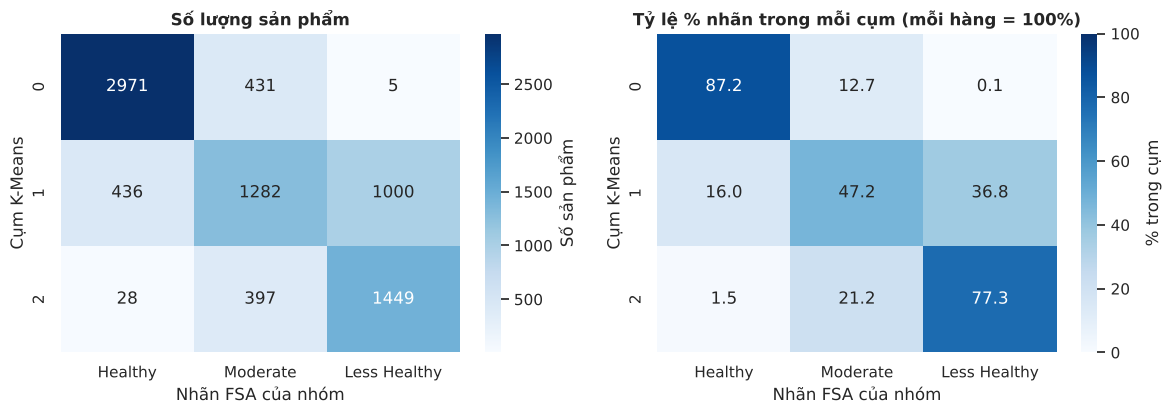

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
sns.heatmap(ct_n[LABELS], annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar_kws={"label": "Số sản phẩm"})
axes[0].set_title("Số lượng sản phẩm", fontweight="bold")
sns.heatmap(ct_p, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, ax=axes[1], cbar_kws={"label": "% trong cụm"})
axes[1].set_title("Tỷ lệ % nhãn trong mỗi cụm (mỗi hàng = 100%)", fontweight="bold")
for ax in axes:
    ax.set_xlabel("Nhãn FSA của nhóm")
    ax.set_ylabel("Cụm K-Means")
plt.tight_layout()
plt.savefig("ml_kmeans_label_heatmap.png", dpi=120)
plt.show()

**Nhận xét:** heatmap có hai ô đậm ở hai đầu (cụm 0 × Healthy và cụm 2 × Less Healthy), tức K-Means tách tốt hai nhóm cực. Hàng giữa (cụm 1) màu loang đều trên cả ba nhãn, nên cụm này không tương ứng với riêng mức nhãn nào. Nhãn Moderate không có cụm "của riêng mình": ô đậm nhất của nó (cụm 1) cũng chỉ chiếm 47,2% cụm.

### 7.3 ARI và NMI giữa K-Means và nhãn của nhóm

In [12]:
ari = adjusted_rand_score(data["health_label"], data["cluster"])
nmi = normalized_mutual_info_score(data["health_label"], data["cluster"])
# Độ thuần (purity): nếu gán mỗi cụm bằng nhãn chiếm đa số thì đúng bao nhiêu % sản phẩm
purity = ct_n[LABELS].max(axis=1).sum() / len(data)
maj = ct_n[LABELS].idxmax(axis=1).to_dict()

print(f"ARI (Adjusted Rand Index)          : {ari:.3f}")
print(f"NMI (Normalized Mutual Information): {nmi:.3f}")
print(f"Purity (gán cụm theo nhãn đa số)   : {purity:.3f}")
print("Nhãn chiếm đa số của từng cụm      :", maj)

# Đối chiếu: các cụm K-Means có giống danh mục sản phẩm không? (mốc tham chiếu)
ari_cat = adjusted_rand_score(data["main_category"], data["cluster"])
nmi_cat = normalized_mutual_info_score(data["main_category"], data["cluster"])
print(f"\nTham chiếu: K-Means vs main_category -> ARI = {ari_cat:.3f}, NMI = {nmi_cat:.3f}")

pd.DataFrame({"chi_so": ["ARI", "NMI", "Purity", "ARI_vs_main_category", "NMI_vs_main_category"],
              "gia_tri": [ari, nmi, purity, ari_cat, nmi_cat]}).to_csv("kmeans_vs_label_metrics.csv", index=False, encoding="utf-8-sig")

ARI (Adjusted Rand Index)          : 0.431
NMI (Normalized Mutual Information): 0.398
Purity (gán cụm theo nhãn đa số)   : 0.713
Nhãn chiếm đa số của từng cụm      : {0: 'Healthy', 1: 'Moderate', 2: 'Less Healthy'}

Tham chiếu: K-Means vs main_category -> ARI = 0.191, NMI = 0.262


**Nhận xét:**
- **ARI = 0,431** và **NMI = 0,398**: hai cách phân nhóm giống nhau ở **mức trung bình, rõ hơn ngẫu nhiên nhiều** (ARI = 0 là ngẫu nhiên, 1 là trùng khớp hoàn toàn) nhưng chưa trùng khớp. Nếu gán mỗi cụm bằng nhãn chiếm đa số thì đúng 71,3% sản phẩm (purity).
- Để có mốc so sánh: K-Means với **danh mục sản phẩm** chỉ đạt ARI = 0,191 và NMI = 0,262, thấp hơn nhiều, nên các cụm phản ánh mức độ dinh dưỡng nhiều hơn là chuyện sản phẩm thuộc loại nào.
- **Lưu ý khi diễn giải:** K-Means dùng cả 4 chất tạo nhãn (chất béo, chất béo bão hòa, đường, muối) mà nhãn FSA cũng được tính từ chính các chất này. Vì vậy một phần sự giống nhau là hiển nhiên, và kết quả này không phải kiểm chứng độc lập hoàn toàn.

### 7.4 Nhận xét tổng hợp: giống và khác nhau giữa K-Means và nhãn FSA

**Giống nhau**
- Hai cách phân nhóm cùng sắp xếp sản phẩm theo một **trục chung từ ít đến nhiều năng lượng, béo, đường**: cụm 0 ↔ Healthy, cụm 2 ↔ Less Healthy. Hai đầu mút khớp rõ (87,2% và 77,3%), và gần như không có sản phẩm nhảy từ Healthy sang Less Healthy hay ngược lại (cụm 0 chỉ có 5 Less Healthy; cụm 2 chỉ 28 Healthy).
- ARI 0,431 và NMI 0,398 cho thấy ba mức nhãn của nhóm **có cơ sở trong cấu trúc dữ liệu**, không phải cách chia tùy ý.

**Khác nhau**
- **Moderate là nhãn khớp kém nhất.** K-Means không tạo ra cụm nào tương ứng với Moderate: nhãn này bị chia vào cả ba cụm (20,4% / 60,8% / 18,8%).
- **Cụm 1 trộn cả ba nhãn** (16,0% Healthy, 47,2% Moderate, 36,8% Less Healthy). Cụm này gom các món nhiều đạm và muối (phần lớn là meals và dairies), trong khi nhãn FSA phân loại theo lượng béo bão hòa, đường, muối cụ thể.
- Nguyên nhân: K-Means chia theo **khoảng cách** trong không gian 6 chất dinh dưỡng (đã log và chuẩn hóa), còn nhãn FSA chia theo **ngưỡng điểm** (Moderate là dải điểm trung gian). Một sản phẩm sát ngưỡng sẽ bị nhãn FSA tách ra, trong khi K-Means vẫn xếp chung cụm với các sản phẩm gần nó.

**Ý nghĩa cho phần mô hình:** K-Means đóng vai trò **kiểm chứng nhãn**: nó xác nhận Healthy và Less Healthy là hai nhóm có thật, đồng thời chỉ ra Moderate là vùng chuyển tiếp mơ hồ. Điều này khớp với mục 8, nơi cả hai mô hình có giám sát đều dự đoán Moderate kém nhất.

## 8. So sánh Logistic Regression và Random Forest

Các chỉ số theo từng lớp (Precision, Recall, F1) và ma trận nhầm lẫn của hai mô hình đã có ở mục 2 và mục 3. Mục này tổng hợp ba chỉ số chính trên **tập test** vào một bảng và một biểu đồ, thêm **Weighted F1** (trung bình F1 có trọng số theo số mẫu mỗi lớp) và F1 theo từng nhãn để chỉ ra nhãn nào dự đoán chưa tốt.

                     Accuracy  Macro F1  Weighted F1
Mô hình                                             
Logistic Regression     0.784     0.761        0.780
Random Forest           0.836     0.827        0.838


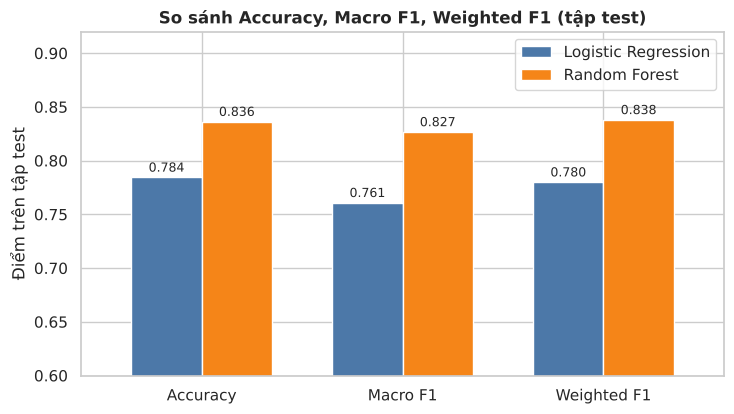


Precision / Recall / F1 theo từng nhãn:
            Mô hình         Nhãn  Precision  Recall    F1  Support
Logistic Regression      Healthy      0.850   0.857 0.854      687
Logistic Regression     Moderate      0.617   0.541 0.577      423
Logistic Regression Less Healthy      0.815   0.892 0.852      490
      Random Forest      Healthy      0.921   0.844 0.881      687
      Random Forest     Moderate      0.691   0.745 0.717      423
      Random Forest Less Healthy      0.862   0.904 0.882      490

F1 theo nhãn (dạng bảng so sánh):
Mô hình       Logistic Regression  Random Forest
Nhãn                                            
Healthy                     0.854          0.881
Moderate                    0.577          0.717
Less Healthy                0.852          0.882

Ma trận nhầm lẫn chuẩn hóa theo nhãn thật (% mỗi hàng):

Logistic Regression
              Healthy  Moderate  Less Healthy
Healthy          85.7      13.2           1.0
Moderate         24.1      54.1         

In [13]:
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

cmp_rows = []
for name in fitted:
    cmp_rows.append({"Mô hình": name,
                     "Accuracy": accuracy_score(y_test, preds[name]),
                     "Macro F1": f1_score(y_test, preds[name], average="macro"),
                     "Weighted F1": f1_score(y_test, preds[name], average="weighted")})
cmp_df = pd.DataFrame(cmp_rows).set_index("Mô hình")
print(cmp_df.round(3).to_string())
cmp_df.round(4).to_csv("model_comparison.csv", encoding="utf-8-sig")

# Biểu đồ cột nhóm
ax = cmp_df.T.plot(kind="bar", figsize=(7.5, 4.3), color=["#4c78a8", "#f58518"], width=0.7)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.3f", padding=2, fontsize=9)
ax.set_ylim(0.6, 0.92)
ax.set_ylabel("Điểm trên tập test")
ax.set_title("So sánh Accuracy, Macro F1, Weighted F1 (tập test)", fontweight="bold")
plt.xticks(rotation=0)
plt.legend(title="")
plt.tight_layout()
plt.savefig("ml_model_comparison.png", dpi=120)
plt.show()

# F1, Precision, Recall theo từng nhãn
per_rows = []
for name in fitted:
    p, r, f, s = precision_recall_fscore_support(y_test, preds[name], labels=LABELS, zero_division=0)
    for i, lab in enumerate(LABELS):
        per_rows.append({"Mô hình": name, "Nhãn": lab, "Precision": p[i], "Recall": r[i], "F1": f[i], "Support": int(s[i])})
per_df = pd.DataFrame(per_rows)
print("\nPrecision / Recall / F1 theo từng nhãn:")
print(per_df.round(3).to_string(index=False))
per_df.round(4).to_csv("per_class_metrics.csv", index=False, encoding="utf-8-sig")

print("\nF1 theo nhãn (dạng bảng so sánh):")
print(per_df.pivot(index="Nhãn", columns="Mô hình", values="F1").reindex(LABELS).round(3).to_string())

# Moderate bị nhầm sang đâu? (tỷ lệ % theo hàng của ma trận nhầm lẫn)
print("\nMa trận nhầm lẫn chuẩn hóa theo nhãn thật (% mỗi hàng):")
for name in fitted:
    cm = confusion_matrix(y_test, preds[name], labels=LABELS)
    print(f"\n{name}")
    print((pd.DataFrame(cm, index=LABELS, columns=LABELS).div(cm.sum(axis=1), axis=0) * 100).round(1).to_string())
    print("Số lượng:"); print(pd.DataFrame(cm, index=LABELS, columns=LABELS).to_string())

**Nhận xét:**
- **Random Forest tốt hơn Logistic Regression ở cả ba chỉ số:** Accuracy 0,836 so với 0,784 (+0,052), Macro F1 0,827 so với 0,761 (+0,066), Weighted F1 0,838 so với 0,780 (+0,058). Chênh lệch Macro F1 lớn hơn Accuracy, nghĩa là Random Forest hơn rõ nhất ở lớp nhỏ và khó (Moderate).
- Macro F1 và Weighted F1 của Random Forest gần nhau (0,827 và 0,838), tức hiệu năng khá đồng đều giữa các lớp. Với Logistic Regression khoảng cách rộng hơn (0,761 so với 0,780) do lớp Moderate kéo Macro F1 xuống.

**Nhãn dự đoán chưa tốt: Moderate, ở cả hai mô hình.**
- F1 của Moderate: Random Forest **0,717**, Logistic Regression **0,577**; hai nhãn còn lại đều ở mức 0,85–0,88 (Random Forest 0,881 và 0,882; Logistic Regression 0,854 và 0,852).
- Logistic Regression chỉ nhận ra 54,1% sản phẩm Moderate (229/423); 24,1% bị đoán là Healthy và 21,7% bị đoán là Less Healthy. Random Forest nhận đúng 74,5% (315/423); phần sai là 11,8% sang Healthy và 13,7% sang Less Healthy.
- Với Random Forest, nhãn Moderate cũng là nhãn có precision thấp nhất (0,691): 94 sản phẩm Healthy và 47 Less Healthy bị đoán nhầm thành Moderate. Lỗi hầu hết xảy ra giữa các lớp kề nhau; Random Forest không đoán Less Healthy thành Healthy lần nào.
- Đây cũng chính là nhãn mà K-Means khớp kém nhất ở mục 7: Moderate là vùng chuyển tiếp, không có ranh giới tự nhiên trong dữ liệu. Vì vậy phần lớn lỗi là do bản chất nhãn trung gian chứ không hẳn do mô hình chọn sai.

**Kết luận:** chọn **Random Forest** làm mô hình chính. Hướng cải thiện Moderate là bổ sung đặc trưng gần với các ngưỡng tính điểm FSA hoặc điều chỉnh ngưỡng quyết định cho lớp này.